In [1]:
import pandas as pd
import numpy as np

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import accuracy_score, f1_score, classification_report

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

# Find the project root if the notebook starts in the notebooks folder
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "career_dataset_large.xlsx"

career_df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", career_df.shape)
print("\nColumn names:")
print(career_df.columns.tolist())

print("\nFirst 5 rows:")
display(career_df.head())

print("\nMissing values:")
print(career_df.isnull().sum())

Dataset loaded successfully!
Dataset shape: (5000, 6)

Column names:
['Education Level', 'Specialization', 'Skills', 'Certifications', 'CGPA/Percentage', 'Recommended Career']

First 5 rows:


,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Recommended Career
0,Bachelor's,Finance,"Counseling, MS Office, Machine Learning",Tally ERP,67,Business Analyst
1,Intermediate,Science,"Accounting, MS Office",AWS Certified,67,Software Engineer
2,Master's,Business,"Accounting, SQL, Data Analysis",Mental Health Basics,90,Financial Analyst
3,Bachelor's,Computer Science,Communication,NaN,75,Clerk
4,Matric,Business,Data Analysis,Tally ERP,83,Sales Assistant



Missing values:
Education Level         0
Specialization          0
Skills                  0
Certifications        596
CGPA/Percentage         0
Recommended Career      0
dtype: int64


In [3]:
# Keep the original dataset unchanged
career_model_df = career_df.copy()

# Check duplicate rows
print("Duplicate rows before cleaning:",
      career_model_df.duplicated().sum())

# Remove duplicate rows
career_model_df = career_model_df.drop_duplicates().copy()

# Fill missing certifications
career_model_df["Certifications"] = (
    career_model_df["Certifications"]
    .fillna("No Certification")
)

# Check results
print("\nDataset shape after cleaning:", career_model_df.shape)

print("\nMissing values after cleaning:")
print(career_model_df.isnull().sum())

print("\nDuplicate rows after cleaning:",
      career_model_df.duplicated().sum())

print("\nCareer categories:")
print(career_model_df["Recommended Career"].nunique())

print("\nRecords per career:")
display(
    career_model_df["Recommended Career"]
    .value_counts()
    .rename_axis("Career")
    .reset_index(name="Count")
)

Duplicate rows before cleaning: 1

Dataset shape after cleaning: (4999, 6)

Missing values after cleaning:
Education Level       0
Specialization        0
Skills                0
Certifications        0
CGPA/Percentage       0
Recommended Career    0
dtype: int64

Duplicate rows after cleaning: 0

Career categories:
12

Records per career:


,Career,Count
0,Clerk,432
1,Marketing Executive,432
2,ML Engineer,428
3,Research Scientist,419
4,Software Engineer,417
5,School Counselor,417
6,Sales Assistant,413
7,Financial Analyst,413
8,Data Entry Operator,413
9,Junior Accountant,413


In [4]:
# Input features
X = career_model_df.drop(columns=["Recommended Career"])

# Target variable
y = career_model_df["Recommended Career"]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining career distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting career distribution:")
display(y_test.value_counts().sort_index())

Training features: (3999, 5)
Testing features: (1000, 5)

Training target: (3999,)
Testing target: (1000,)

Training career distribution:


Recommended Career
Business Analyst       316
Clerk                  346
Data Entry Operator    330
Financial Analyst      330
Junior Accountant      330
ML Engineer            342
Marketing Executive    346
Professor              326
Research Scientist     335
Sales Assistant        330
School Counselor       334
Software Engineer      334
Name: count, dtype: int64


Testing career distribution:


Recommended Career
Business Analyst       79
Clerk                  86
Data Entry Operator    83
Financial Analyst      83
Junior Accountant      83
ML Engineer            86
Marketing Executive    86
Professor              81
Research Scientist     84
Sales Assistant        83
School Counselor       83
Software Engineer      83
Name: count, dtype: int64

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# Numerical feature
numeric_features = ["CGPA/Percentage"]

# Categorical features
categorical_features = [
    "Education Level",
    "Specialization",
    "Certifications"
]

# Text feature
text_feature = "Skills"

# Build preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "skills",
            TfidfVectorizer(),
            text_feature
        )
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data without refitting
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

Preprocessing completed successfully!
Training matrix shape: (3999, 35)
Testing matrix shape: (1000, 35)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from xgboost import XGBClassifier

# Encode career labels for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Define models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        max_depth=5,
        learning_rate=0.1,
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    ),

    "Dummy Baseline": DummyClassifier(
        strategy="most_frequent"
    )
}

results = []
trained_models = {}

# Train and evaluate every model
for name, model in models.items():

    if name == "XGBoost":
        model.fit(X_train_processed, y_train_encoded)
        predictions = model.predict(X_test_processed)
    else:
        model.fit(X_train_processed, y_train)
        predictions = model.predict(X_test_processed)

    # Convert XGBoost predictions back to career labels
    if name == "XGBoost":
        predictions = label_encoder.inverse_transform(
            predictions.astype(int)
        )

    accuracy = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(
        y_test,
        predictions,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy * 100, 2),
        "Macro F1 (%)": round(macro_f1 * 100, 2)
    })

    trained_models[name] = model

    print(f"{name} training completed.")

# Display comparison
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Macro F1 (%)",
    ascending=False
).reset_index(drop=True)

print("\nMODEL COMPARISON")
display(results_df)

Logistic Regression training completed.
Random Forest training completed.
XGBoost training completed.
Dummy Baseline training completed.

MODEL COMPARISON


,Model,Accuracy (%),Macro F1 (%)
0,XGBoost,8.9,8.82
1,Random Forest,8.1,8.06
2,Logistic Regression,7.1,6.73
3,Dummy Baseline,8.6,1.32


XGBOOST CLASSIFICATION REPORT

                     precision    recall  f1-score   support

   Business Analyst       0.11      0.10      0.10        79
              Clerk       0.11      0.13      0.12        86
Data Entry Operator       0.15      0.13      0.14        83
  Financial Analyst       0.10      0.12      0.11        83
  Junior Accountant       0.10      0.10      0.10        83
        ML Engineer       0.04      0.05      0.05        86
Marketing Executive       0.11      0.10      0.11        86
          Professor       0.06      0.05      0.05        81
 Research Scientist       0.05      0.05      0.05        84
    Sales Assistant       0.06      0.05      0.05        83
   School Counselor       0.09      0.07      0.08        83
  Software Engineer       0.10      0.12      0.11        83

           accuracy                           0.09      1000
          macro avg       0.09      0.09      0.09      1000
       weighted avg       0.09      0.09      0.09  

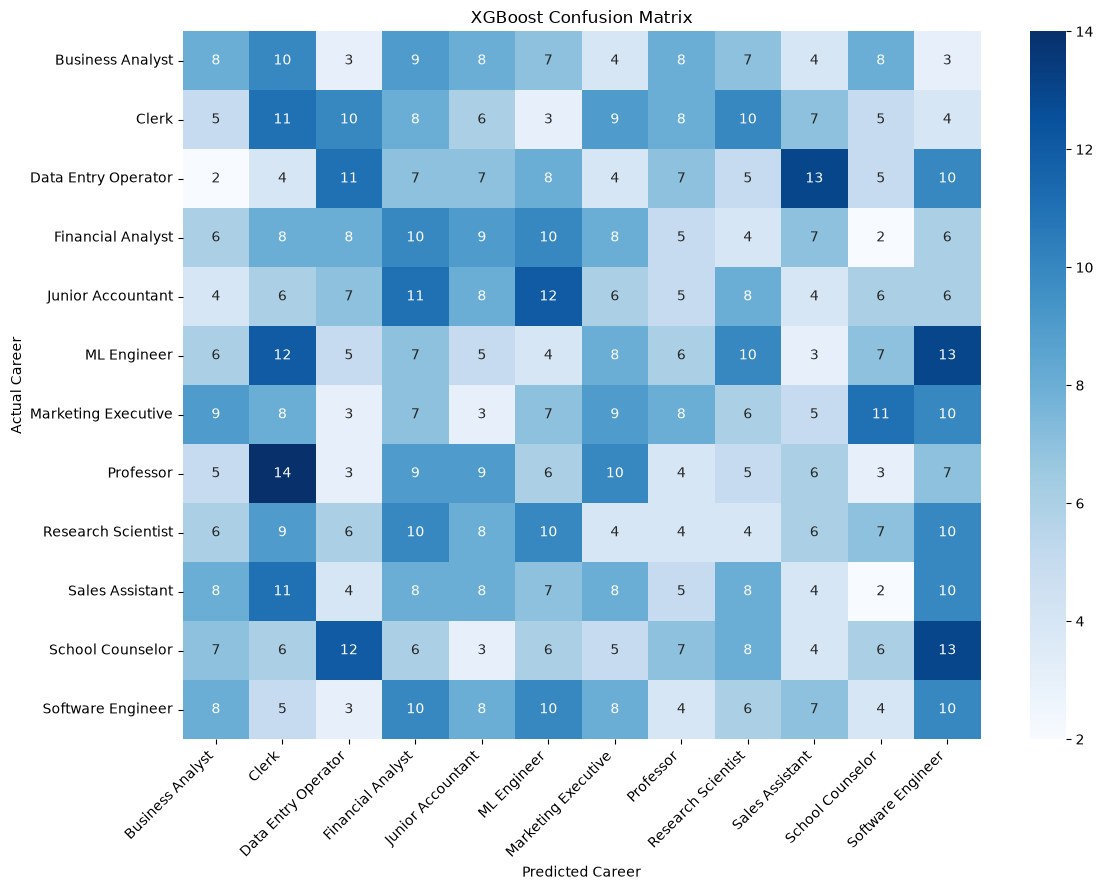

In [7]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Get XGBoost predictions
xgb_predictions_encoded = trained_models["XGBoost"].predict(
    X_test_processed
)

xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

# Classification report
print("XGBOOST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        xgb_predictions,
        labels=label_encoder.classes_,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    xgb_predictions,
    labels=label_encoder.classes_
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted Career")
plt.ylabel("Actual Career")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
# Identify profiles with identical input features
feature_columns = [
    "Education Level",
    "Specialization",
    "Skills",
    "Certifications",
    "CGPA/Percentage"
]

profile_analysis = (
    career_model_df
    .groupby(feature_columns, dropna=False)
    .agg(
        Number_of_Records=("Recommended Career", "size"),
        Number_of_Careers=("Recommended Career", "nunique"),
        Career_Labels=(
            "Recommended Career",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

# Profiles associated with more than one career
conflicting_profiles = profile_analysis[
    profile_analysis["Number_of_Careers"] > 1
]

print("Total unique input profiles:", len(profile_analysis))

print("Conflicting input profiles:", len(conflicting_profiles))

print(
    "Records belonging to conflicting profiles:",
    conflicting_profiles["Number_of_Records"].sum()
)

print("\nExamples of conflicting profiles:")
display(conflicting_profiles.head(10))

Total unique input profiles: 4984
Conflicting input profiles: 15
Records belonging to conflicting profiles: 30

Examples of conflicting profiles:


,Education Level,Specialization,Skills,Certifications,CGPA/Percentage,Number_of_Records,Number_of_Careers,Career_Labels
43,Bachelor's,Arts,"Data Analysis, MS Office",Creative Writing,86,2,2,"Data Entry Operator, Junior Accountant"
757,Bachelor's,Psychology,Accounting,Google Data Analytics,65,2,2,"Clerk, Marketing Executive"
784,Bachelor's,Psychology,"Communication, Python",No Certification,91,2,2,"Financial Analyst, Software Engineer"
816,Bachelor's,Psychology,MS Office,No Certification,75,2,2,"Data Entry Operator, ML Engineer"
1249,Intermediate,Business,Python,Google Data Analytics,83,2,2,"Data Entry Operator, Marketing Executive"
1558,Intermediate,Engineering,MS Office,Mental Health Basics,87,2,2,"ML Engineer, Professor"
1639,Intermediate,Finance,Communication,AWS Certified,81,2,2,"Professor, Software Engineer"
1662,Intermediate,Finance,Data Analysis,AWS Certified,75,2,2,"Clerk, Professor"
1806,Intermediate,Psychology,Financial Analysis,AWS Certified,65,2,2,"Data Entry Operator, School Counselor"
2333,Master's,Commerce,Python,AWS Certified,92,2,2,"Marketing Executive, Professor"


In [9]:
# Create a diagnostic dataset without conflicting profiles
conflicting_keys = conflicting_profiles[feature_columns]

consistent_df = career_model_df.merge(
    conflicting_keys[feature_columns].drop_duplicates(),
    on=feature_columns,
    how="left",
    indicator=True
)

career_df_consistent = (
    consistent_df[consistent_df["_merge"] == "left_only"]
    .drop(columns=["_merge"])
    .reset_index(drop=True)
)

print("Original cleaned dataset:", career_model_df.shape)
print("Dataset without conflicting profiles:", career_df_consistent.shape)

print(
    "\nRemaining career categories:",
    career_df_consistent["Recommended Career"].nunique()
)

print("\nRecords per career:")
display(
    career_df_consistent["Recommended Career"]
    .value_counts()
    .sort_index()
)

Original cleaned dataset: (4999, 6)
Dataset without conflicting profiles: (4969, 6)

Remaining career categories: 12

Records per career:


Recommended Career
Business Analyst       394
Clerk                  429
Data Entry Operator    409
Financial Analyst      410
Junior Accountant      411
ML Engineer            426
Marketing Executive    427
Professor              403
Research Scientist     417
Sales Assistant        413
School Counselor       416
Software Engineer      414
Name: count, dtype: int64

In [10]:
# Separate features and target
X_consistent = career_df_consistent.drop(
    columns=["Recommended Career"]
)

y_consistent = career_df_consistent["Recommended Career"]

# Stratified train-test split
X_train_consistent, X_test_consistent, y_train_consistent, y_test_consistent = (
    train_test_split(
        X_consistent,
        y_consistent,
        test_size=0.20,
        random_state=42,
        stratify=y_consistent
    )
)

print("Training features:", X_train_consistent.shape)
print("Testing features:", X_test_consistent.shape)

print("\nTraining target:", y_train_consistent.shape)
print("Testing target:", y_test_consistent.shape)

print("\nTraining career categories:", y_train_consistent.nunique())
print("Testing career categories:", y_test_consistent.nunique())

Training features: (3975, 5)
Testing features: (994, 5)

Training target: (3975,)
Testing target: (994,)

Training career categories: 12
Testing career categories: 12


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

preprocessor_consistent = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            ["CGPA/Percentage"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            [
                "Education Level",
                "Specialization",
                "Certifications"
            ]
        ),
        (
            "skills",
            TfidfVectorizer(),
            "Skills"
        )
    ]
)

# Fit only on training data
X_train_consistent_processed = (
    preprocessor_consistent.fit_transform(
        X_train_consistent
    )
)

# Transform test data
X_test_consistent_processed = (
    preprocessor_consistent.transform(
        X_test_consistent
    )
)

print("Consistent dataset preprocessing completed!")
print(
    "Training matrix:",
    X_train_consistent_processed.shape
)
print(
    "Testing matrix:",
    X_test_consistent_processed.shape
)

Consistent dataset preprocessing completed!
Training matrix: (3975, 35)
Testing matrix: (994, 35)


In [12]:
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier
import pandas as pd

# Encode career labels for XGBoost
label_encoder_consistent = LabelEncoder()

y_train_encoded = label_encoder_consistent.fit_transform(
    y_train_consistent
)

y_test_encoded = label_encoder_consistent.transform(
    y_test_consistent
)

# Train XGBoost
xgb_consistent = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=len(label_encoder_consistent.classes_),
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_consistent.fit(
    X_train_consistent_processed,
    y_train_encoded
)

# XGBoost predictions
xgb_predictions_encoded = xgb_consistent.predict(
    X_test_consistent_processed
)

xgb_predictions = label_encoder_consistent.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

# Majority-class baseline
dummy_consistent = DummyClassifier(
    strategy="most_frequent"
)

dummy_consistent.fit(
    X_train_consistent_processed,
    y_train_consistent
)

dummy_predictions = dummy_consistent.predict(
    X_test_consistent_processed
)

# Compare metrics
comparison = pd.DataFrame([
    {
        "Model": "XGBoost",
        "Accuracy (%)": round(
            accuracy_score(y_test_consistent, xgb_predictions) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(
                y_test_consistent,
                xgb_predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        )
    },
    {
        "Model": "Dummy Baseline",
        "Accuracy (%)": round(
            accuracy_score(y_test_consistent, dummy_predictions) * 100, 2
        ),
        "Macro F1 (%)": round(
            f1_score(
                y_test_consistent,
                dummy_predictions,
                average="macro",
                zero_division=0
            ) * 100, 2
        )
    }
])

display(comparison)

,Model,Accuracy (%),Macro F1 (%)
0,XGBoost,7.85,7.87
1,Dummy Baseline,8.65,1.33


In [13]:
# Analyze skills associated with each career
skill_analysis = career_model_df[
    ["Skills", "Recommended Career"]
].copy()

skill_analysis["Skill_List"] = (
    skill_analysis["Skills"]
    .str.split(",")
    .apply(
        lambda skills: [
            skill.strip() for skill in skills
        ]
    )
)

skill_rows = skill_analysis.explode("Skill_List")

skill_counts = (
    skill_rows
    .groupby(["Recommended Career", "Skill_List"])
    .size()
    .reset_index(name="Count")
)

skill_counts["Percentage (%)"] = (
    skill_counts["Count"]
    / skill_counts.groupby("Recommended Career")["Count"]
        .transform("sum")
    * 100
).round(2)

print("Total unique skills:", skill_rows["Skill_List"].nunique())

print("\nTop 5 skills for each career:")

for career in sorted(skill_counts["Recommended Career"].unique()):
    print(f"\n{career}")

    display(
        skill_counts[
            skill_counts["Recommended Career"] == career
        ]
        .sort_values("Percentage (%)", ascending=False)
        .head(5)[["Skill_List", "Count", "Percentage (%)"]]
        .reset_index(drop=True)
    )

Total unique skills: 10

Top 5 skills for each career:

Business Analyst


,Skill_List,Count,Percentage (%)
0,Python,86,10.89
1,Financial Analysis,86,10.89
2,Counseling,85,10.76
3,MS Office,81,10.25
4,Machine Learning,81,10.25



Clerk


,Skill_List,Count,Percentage (%)
0,Accounting,93,11.70
1,SQL,85,10.69
2,Python,83,10.44
3,Data Analysis,83,10.44
4,Machine Learning,81,10.19



Data Entry Operator


...

,Skill_List,Count,Percentage (%)
0,Python,99,11.81
1,Counseling,94,11.22
2,Marketing,90,10.74
3,MS Office,88,10.50
4,Financial Analysis,84,10.02



School Counselor


,Skill_List,Count,Percentage (%)
0,Machine Learning,89,11.04
1,SQL,89,11.04
2,Python,85,10.55
3,Marketing,85,10.55
4,Data Analysis,85,10.55



Software Engineer


,Skill_List,Count,Percentage (%)
0,Python,97,11.77
1,Accounting,90,10.92
2,SQL,86,10.44
3,Communication,85,10.32
4,Marketing,81,9.83


In [16]:
import sys
from pathlib import Path

# Set the project root
PROJECT_ROOT = Path(
    r"C:\Users\ADMIN\OneDrive\Desktop\SkillPath-AI"
)

# Add the project root to Python's import path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import the recommender
from src.career.recommender import recommend_careers

print("Recommender imported successfully!")

Recommender imported successfully!


In [17]:
sample_skills = ["Python", "SQL", "Data Analysis"]

recommendations = recommend_careers(
    user_skills=sample_skills,
    top_n=5
)

display(recommendations)

,Career,Matched Skills,Match Score (%)
0,Business Analyst,"data analysis, python, sql",100.0
1,Clerk,"data analysis, python, sql",100.0
2,Data Entry Operator,"data analysis, python, sql",100.0
3,Financial Analyst,"data analysis, python, sql",100.0
4,ML Engineer,"data analysis, python, sql",100.0


In [20]:
import importlib
import src.career.recommender as career_recommender

importlib.reload(career_recommender)

recommendations = career_recommender.recommend_careers(
    user_skills=["Python", "SQL", "Data Analysis"],
    top_n=5
)

display(recommendations)

,Career,Matched Skills,Match Score (%)
0,Marketing Executive,"data analysis, python, sql",58.10
1,Junior Accountant,"data analysis, python, sql",55.21
2,Software Engineer,"data analysis, python, sql",54.68
3,School Counselor,"data analysis, python, sql",53.48
4,Financial Analyst,"data analysis, python, sql",52.54


In [21]:
test_profiles = {
    "Software Profile": ["Python", "SQL", "Machine Learning"],
    "Analytics Profile": ["Python", "SQL", "Data Analysis"],
    "Business Profile": ["Marketing", "Communication", "MS Office"]
}

for profile_name, skills in test_profiles.items():
    print(f"\n{profile_name}: {skills}")

    display(
        career_recommender.recommend_careers(
            user_skills=skills,
            top_n=5
        )
    )


Software Profile: ['Python', 'SQL', 'Machine Learning']


,Career,Matched Skills,Match Score (%)
0,Marketing Executive,"machine learning, python, sql",57.87
1,Software Engineer,"machine learning, python, sql",56.59
2,School Counselor,"machine learning, python, sql",53.00
3,Sales Assistant,"machine learning, python, sql",52.06
4,ML Engineer,"machine learning, python, sql",51.17



Analytics Profile: ['Python', 'SQL', 'Data Analysis']


,Career,Matched Skills,Match Score (%)
0,Marketing Executive,"data analysis, python, sql",58.10
1,Junior Accountant,"data analysis, python, sql",55.21
2,Software Engineer,"data analysis, python, sql",54.68
3,School Counselor,"data analysis, python, sql",53.48
4,Financial Analyst,"data analysis, python, sql",52.54



Business Profile: ['Marketing', 'Communication', 'MS Office']


,Career,Matched Skills,Match Score (%)
0,Data Entry Operator,"communication, marketing, ms office",56.42
1,Sales Assistant,"communication, marketing, ms office",54.24
2,Financial Analyst,"communication, marketing, ms office",54.00
3,Marketing Executive,"communication, marketing, ms office",53.94
4,Junior Accountant,"communication, marketing, ms office",52.78
